In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc
import os
import matplotlib.gridspec as gridspec


In [2]:
def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% R;Z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['R','Z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    #print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    #print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    #print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    #print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                #print('loop start')
                #print(f"Processing param: {param}")
                #print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    #print(df.columns)
                    r = raw_row['R']
                    z = raw_row['Z']

                    output_df.at[row_idx, 'R'] = r
                    output_df.at[row_idx, 'Z'] = z
                    
                    for var_name in var_names:
                        #print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df




In [6]:
data_dir = r'../../data/simple_conduit_source_deformation/example_plot_data'
df_list = []
for filename in os.listdir(data_dir):
    if filename.endswith('.txt'):
        filepath = os.path.join(data_dir, filename)
        df = parse_comsol_edge_data(filepath,var_names=['z_edifice', 'C_source', 'C_depth', 'C_R', 'param_def', 'P_in'])
        df_list.append(df)

data_df = pd.concat(df_list, ignore_index=True)


In [7]:
# Find unique combinations of parameters in df
var_names = ['z_edifice', 'C_source', 'C_depth', 'C_R', 'param_def', 'P_in']
if 'data_df' in locals():
    unique_combinations = data_df[var_names].drop_duplicates()
    print(f"Number of unique combinations: {len(unique_combinations)}")
    print(unique_combinations.head(100))
else:
    print("DataFrame 'data_df' not found. Please run the data loading cell first.")


Number of unique combinations: 9
     z_edifice C_source C_depth   C_R param_def        P_in
0       2000.0    500.0   250.0  15.0       0.0  20000000.0
338     2000.0    500.0   250.0  15.0       3.0  20000000.0
676     2000.0    500.0   250.0  15.0       4.0  20000000.0
1014    1000.0    500.0   250.0  15.0       0.0  20000000.0
1292    1000.0    500.0   250.0  15.0       3.0  20000000.0
1570    1000.0    500.0   250.0  15.0       4.0  20000000.0
1848       0.0    500.0   250.0  15.0       0.0  20000000.0
2103       0.0    500.0   250.0  15.0       3.0  20000000.0
2358       0.0    500.0   250.0  15.0       4.0  20000000.0


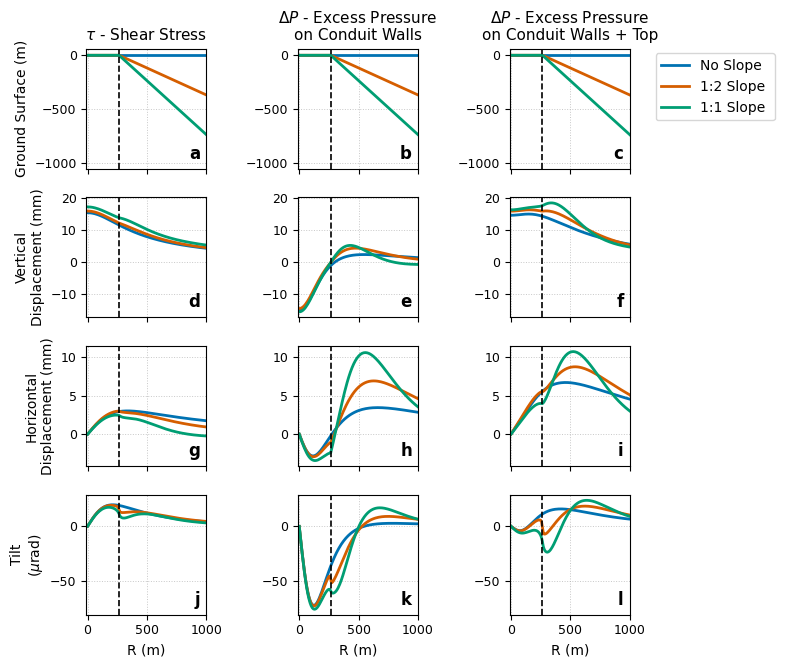

In [17]:


color_list = ['#0072B2', '#D55E00', '#009E73']  # blue, orange, green
unique_z_edifice = np.sort(data_df['z_edifice'].dropna().unique())
color_dict = dict(zip(unique_z_edifice, color_list))

# Convert displacement columns from meters to mm
data_df = data_df.copy()
data_df['w2_mm'] = data_df['w2']*1000
data_df['u2_mm'] = data_df['u2'] * 1000
data_df['solid.RotrZ_micro'] = data_df['solid.RotrZ'] * 1e6  # Convert to microradians
param_def_dict = {
    0: '$\\tau$ - Shear Stress',
    3: '$\Delta P$ - Excess Pressure\non Conduit Walls',
    4: '$\Delta P$ - Excess Pressure\non Conduit Walls + Top'
}
var_dict = {
    'w2_mm': 'Vertical\nDisplacement (mm)',
    'u2_mm': 'Horizontal\nDisplacement (mm)',
    'solid.RotrZ_micro': 'Tilt\n($\mu$rad)'
}

z_dict = {
    1000: '1:2 Slope ',
    2000: '1:1 Slope',
    0: 'No Slope'
}

param_defs = [0, 3, 4]
variables = ['w2_mm', 'u2_mm', 'solid.RotrZ_micro']

def add_margin(lims, margin=0.05):
    span = lims[1] - lims[0]
    return (lims[0] - margin * span, lims[1] + margin * span)

ylim_row0 = add_margin((-1000,10))
ylim_row1 = add_margin((data_df['w2_mm'].min(), data_df['w2_mm'].max()))
ylim_row2 = add_margin((data_df['u2_mm'].min(), data_df['u2_mm'].max()))
ylim_row3 = add_margin((data_df['solid.RotrZ_micro'].min(), data_df['solid.RotrZ_micro'].max()))
ylims = [ylim_row0, ylim_row1, ylim_row2, ylim_row3]

xmin, xmax = -10, 1000

fig,axes = plt.subplots(4,3,figsize=(7, 7),sharex=True)

# For collecting legend handles/labels
handles, labels = [], []


for col, param_def in enumerate(param_defs):
    ax = axes[0][col]
    subset = data_df[data_df['param_def'] == param_def]
    for i, z_edifice in enumerate(unique_z_edifice):
        subsub = subset[subset['z_edifice'] == z_edifice]
        if not subsub.empty:
            line, = ax.plot(subsub['R'], subsub['Z'], label=f'z_edifice={z_edifice}', color=color_dict[z_edifice], lw=2)
            if col == 0:
                handles.append(line)
                labels.append(f'{z_dict.get(z_edifice, "default")}')
    # Only set y label for first column
    if col == 0:
        ax.set_ylabel('Ground Surface (m)')
    else:
        ax.set_ylabel('')
    # Only set x label for bottom row
    ax.set_xlabel('' if 0 != 3 else 'R (m)')
    ax.set_title(param_def_dict.get(param_def, str(param_def)), fontsize=11)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(*ylims[0])
    ax.axvline(265, color='k', linestyle='--', lw=1.2)
    ax.grid(True, which='both', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.set_box_aspect(1)
    #ax.set_aspect('equal') 
for row, var in enumerate(variables, start=1):
    for col, param_def in enumerate(param_defs):
        ax = axes[row][col]
        subset = data_df[data_df['param_def'] == param_def]
        for i, z_edifice in enumerate(unique_z_edifice):
            subsub = subset[subset['z_edifice'] == z_edifice]
            if not subsub.empty:
                ax.plot(subsub['R'], subsub[var], color=color_dict[z_edifice], lw=2)
        # Only set y label for first column
        if col == 0:
            ax.set_ylabel(var_dict.get(var, var))
        else:
            ax.set_ylabel('')
        # Only set x label for bottom row
        if row == 3:
            ax.set_xlabel('R (m)')
        else:
            ax.set_xlabel('')
         # Make all subplots square

        ax.set_xlim(xmin, xmax)
        ax.set_ylim(*ylims[row])
        ax.axvline(265, color='k', linestyle='--', lw=1.2)
        ax.grid(True, which='both', linestyle=':', linewidth=0.7, alpha=0.7)
        ax.set_box_aspect(1)
for row_axes in axes:
    for ax in row_axes:
        ax.tick_params(axis='both', which='major', labelsize=9)
        ax.xaxis.label.set_size(10)
        ax.yaxis.label.set_size(10)

# Single legend for the whole figure
fig.legend(handles, labels, loc='upper center', ncol=1, fontsize=10, frameon=True, bbox_to_anchor=(1.05, 0.90))
# Label each subplot with a letter in the bottom right corner
for i, row_axes in enumerate(axes):
    for j, ax in enumerate(row_axes):
        label = chr(97 + i*3 + j)  # Generate labels a, b, c, ...
        ax.text(0.95, 0.05, label, transform=ax.transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right')


plt.tight_layout(rect=[0, 0, 1, 0.98])


# save as pdf 
plt.savefig('../../output_plots/1/fig_01_simple_geodetic_model_plot.pdf', bbox_inches='tight')



In [9]:



def load_max_along_edge_comsol(filepath,param_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% u2'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    unique_vars = []
    for i, col in enumerate(columns):
        var_name = col.split('@')[0]
        if var_name not in unique_vars:
            unique_vars.append(var_name)
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}
    no_combinations = len(columns)//len(unique_vars)

    data_lines = lines[data_start:]

    # check that there is only 1 line of data
    if len(data_lines) > 1:
        print(f"Warning: More than one line of data found. Only the first line will be parsed. Total lines: {len(data_lines)}")
        
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    cols = len(unique_vars)
    rows = len(data_rows[0])//len(unique_vars)

    # reshape list into 2d array with rows and cols
    data_array = np.array(data_rows[0]).reshape((rows, cols))

    # make empty array with np.nan columns for each parameter and length of no_combinations
    param_array = np.full((no_combinations, len(param_names)), np.nan)

    for j,col in enumerate(columns[::len(unique_vars)]):
        for i,param in enumerate(col.split('@')[1].split(',')):
            param_array[j,i] = float(param.split('=')[1])

    # compare size of param array and data array
    if param_array.shape[0] != data_array.shape[0]:
        print(f"Warning: Number of rows in parameter array ({param_array.shape[0]}) does not match number of rows in data array ({data_array.shape[0]}).")
    # print size of param array and data array
    print(f"Parameter array shape: {param_array.shape}")
    print(f"Data array shape: {data_array.shape}")
    # stack columns of data_array to param_array to make final dataframe
    final_array = np.hstack((param_array, data_array))

    df = pd.DataFrame(index=range(no_combinations),columns=param_names+unique_vars,data=final_array)
    # remove spaces from §df.columns
    df.columns = df.columns.str.strip()
    return df



In [11]:
def combined_abs_min_max(filepath_min,filepath_max,param_names):
    df_max = load_max_along_edge_comsol(filepath_max_0_250, param_names)

    df_min = load_max_along_edge_comsol(filepath_min_0_250, param_names)

    # create empty new df where the absolute maximum value is kept 
    df = pd.DataFrame(columns=df_max.columns)
    for var in ['u2 (m)', 'w2 (m)', 'solid.RotrZ (rad)']:
        # find unique combinations of parameters in df_max
        unique_params = df_max[param_names].drop_duplicates()
        for i, params in unique_params.iterrows():

            if abs(df_max[var][i]) > abs(df_min[var][i]):
                df.at[i, var] = df_max[var][i]
            else:
                df.at[i, var] = df_min[var][i]

            # also copy the parameter values to the new df
            for param in param_names:
                df.at[i, param] = params[param]

    df['abs w2'] = abs(df['w2 (m)'])
    df['abs u2'] = abs(df['u2 (m)'])
    df['abs solid.RotrZ micro'] = abs(df['solid.RotrZ (rad)'] * 1e6)  # Convert to microradians
    return df



In [18]:

filepath_max_0_250 = '../../data/simple_conduit_source_deformation/max_deformation/GE_max_29may2026.txt'

filepath_min_0_250 = '../../data/simple_conduit_source_deformation/max_deformation/GE_min_29may2026.txt'



param_names = ['C_R', 'z_edifice', 'C_source', 'C_depth', 'param_def', 'P_in']

df_0_250 = combined_abs_min_max(filepath_min_0_250,filepath_max_0_250,param_names)


Parameter array shape: (594, 6)
Data array shape: (594, 4)
Parameter array shape: (594, 6)
Data array shape: (594, 4)


In [ ]:
df_0_250

/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_56745/873805849.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.98])


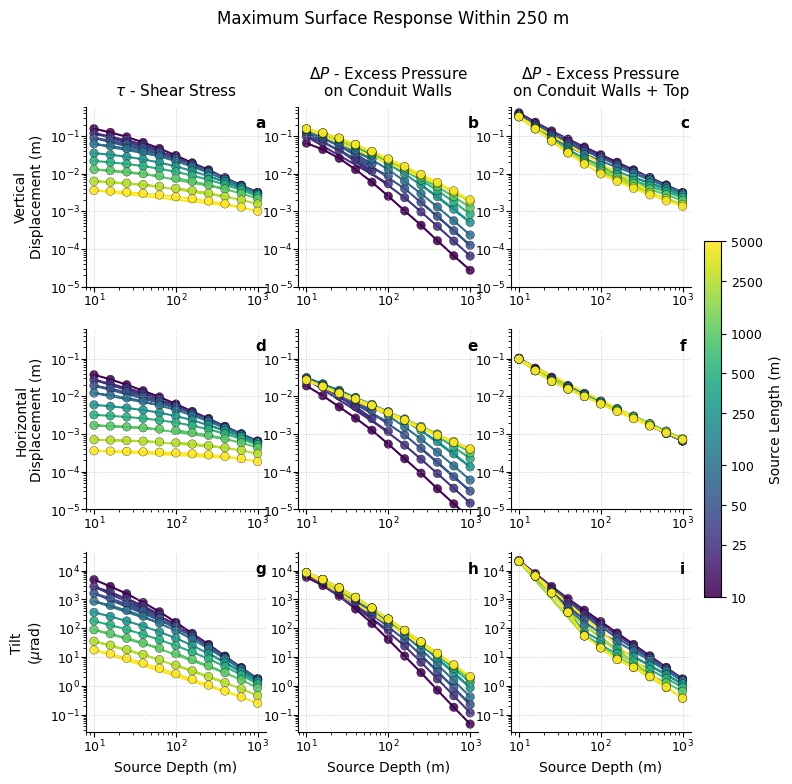

In [16]:
# Publication-style 3x3 panel: columns = forcing type, rows = max variable within 250 m
fig, axes = plt.subplots(
    3, 3, figsize=(8.2, 8.2), sharex=True, sharey='row',
    gridspec_kw={'wspace': 0.18, 'hspace': 0.20}
 )

cmap = plt.cm.viridis
plt.rcParams.update({
    "font.size": 13,          # base text
    "axes.titlesize": 14,     # subplot titles
    "axes.labelsize": 13,     # axis labels
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 14
})
# Column labels (forcing type)
param_def_dict = {
    0: '$\\tau$ - Shear Stress',
    3: '$\\Delta P$ - Excess Pressure\non Conduit Walls',
    4: '$\\Delta P$ - Excess Pressure\non Conduit Walls + Top'
}

# Row labels (maximum variable within 250 m)
var_dict = {
    'abs w2': 'Vertical\nDisplacement (m)',
    'abs u2': 'Horizontal\nDisplacement (m)',
    'abs solid.RotrZ micro': 'Tilt\n($\mu$rad)'
}

# Mapping from display variable keys to dataframe column names in df_0_250
df_col_map = {
    'abs w2': 'abs w2',
    'abs u2': 'abs u2',
    'abs solid.RotrZ micro': 'abs solid.RotrZ micro'
}
row_vars = ['abs w2', 'abs u2', 'abs solid.RotrZ micro']
param_defs = [0, 3, 4]

df_list = [df_0_250]
df_linestyles = ['-', '--']

# Color by conduit source length in log10 space
unique_C_source = np.array(sorted(df_0_250['C_source'].dropna().astype(float).unique()))
norm = plt.Normalize(np.log10(unique_C_source.min()), np.log10(unique_C_source.max()))

C_R = 10
scatter_handle = None
for k, df in enumerate(df_list):
    df = df.copy()
    df['log10_c_source'] = np.log10(df['C_source'].astype(float))
    for col, param_def in enumerate(param_defs):
        subset = df[(df['param_def'] == param_def) & (df['C_R'] == C_R)].copy()
        subset = subset.sort_values('C_source')

        # Column titles
        axes[0, col].set_title(param_def_dict.get(param_def, str(param_def)), fontsize=11, pad=8)

        for row, var_key in enumerate(row_vars):
            ax = axes[row, col]
            ycol = df_col_map[var_key]

            for C_source in unique_C_source:
                subsub = subset[subset['C_source'].astype(float) == C_source]
                if not subsub.empty:
                    ax.plot(
                        subsub['C_depth'],
                        subsub[ycol],
                        color=plt.cm.viridis(norm(np.log10(C_source))),
                        lw=1.5,
                        zorder=1,
                        linestyle=df_linestyles[k]
                    )

            scatter_handle = ax.scatter(
                subset['C_depth'],
                subset[ycol],
                c=subset['log10_c_source'],
                cmap=cmap,
                norm=norm,
                s=38,
                edgecolors='k',
                linewidths=0.25,
                alpha=0.88
            )

            # Publication formatting
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.grid(True, which='major', linestyle=':', linewidth=0.7, alpha=0.65)
            ax.tick_params(axis='both', which='major', labelsize=9, direction='out')
            ax.set_box_aspect(1)  # make each subplot square

            # Row labels only on first column
            if col == 0:
                ax.set_ylabel(var_dict[var_key], fontsize=10)
            else:
                ax.set_ylabel('')

            # X labels only on bottom row
            if row == 2:
                ax.set_xlabel('Source Depth (m)', fontsize=10)
            else:
                ax.set_xlabel('')

# Add panel labels (a-i)
for i in range(3):
    for j in range(3):
        panel_label = chr(97 + i * 3 + j)
        axes[i, j].text(
            0.94, 0.95, panel_label, transform=axes[i, j].transAxes,
            fontsize=11, fontweight='bold', va='top', ha='left'
        )
for ax in axes[:2,:].flatten():
    ax.set_ylim([1e-5,0.6])
for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)  # hide top/right ticks
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis='both', which='major', pad=0.5)   # try 0–2 for tighter spacing
    ax.tick_params(axis='both', which='minor', pad=0.5)
# Shared colorbar: positions in log10 space, labels in original C_source values
cbar = fig.colorbar(
    scatter_handle, ax=axes.ravel().tolist(), fraction=0.028, pad=0.02
 )
cbar.set_label('Source Length (m)', fontsize=10)
cbar.ax.tick_params(labelsize=9)

tick_positions = np.log10(unique_C_source)
tick_labels = [f'{v:g}' for v in unique_C_source]
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)

fig.suptitle('Maximum Surface Response Within 250 m', fontsize=12, y=0.995)
plt.tight_layout(rect=[0, 0, 0.95, 0.98])
# save figure as pdf 
plt.savefig('../../output_plots/1/fig_max_surface_response_CR_10.pdf', format='pdf', bbox_inches='tight')

plt.show()

Plotting variable 'abs w2' for param_def=0 and C_R=50
Plotting variable 'abs u2' for param_def=0 and C_R=50
Plotting variable 'abs solid.RotrZ micro' for param_def=0 and C_R=50
Plotting variable 'abs w2' for param_def=3 and C_R=50
Plotting variable 'abs u2' for param_def=3 and C_R=50
Plotting variable 'abs solid.RotrZ micro' for param_def=3 and C_R=50
Plotting variable 'abs w2' for param_def=4 and C_R=50
Plotting variable 'abs u2' for param_def=4 and C_R=50
Plotting variable 'abs solid.RotrZ micro' for param_def=4 and C_R=50


/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_56745/1414923302.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.98])


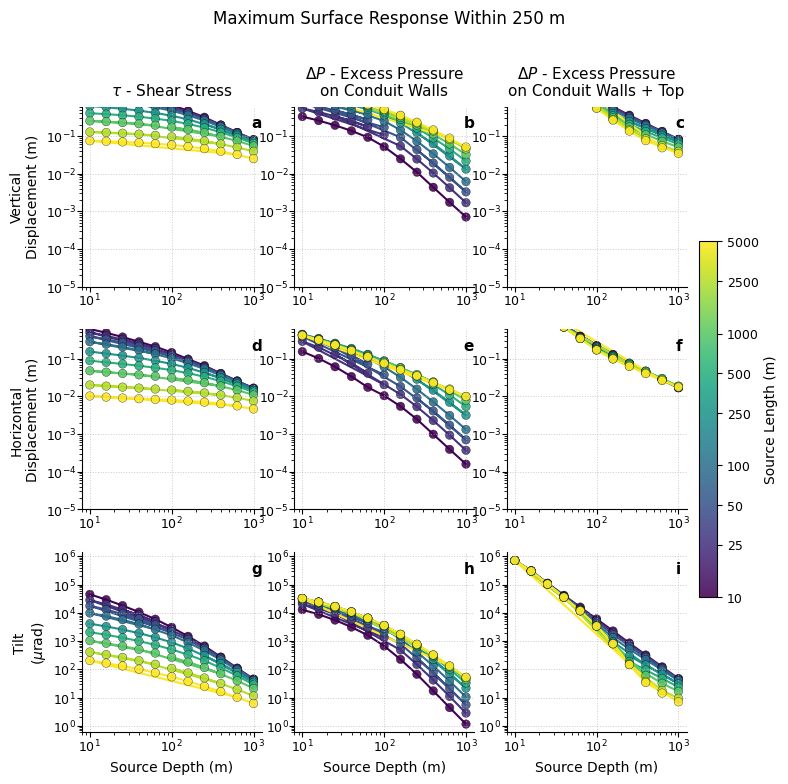

In [14]:
# Publication-style 3x3 panel: columns = forcing type, rows = max variable within 250 m
fig, axes = plt.subplots(
    3, 3, figsize=(8.2, 8.2), sharex=True, sharey='row',
    gridspec_kw={'wspace': 0.18, 'hspace': 0.20}
 )

cmap = plt.cm.viridis
plt.rcParams.update({
    "font.size": 13,          # base text
    "axes.titlesize": 14,     # subplot titles
    "axes.labelsize": 13,     # axis labels
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 14
})
# Column labels (forcing type)
param_def_dict = {
    0: '$\\tau$ - Shear Stress',
    3: '$\\Delta P$ - Excess Pressure\non Conduit Walls',
    4: '$\\Delta P$ - Excess Pressure\non Conduit Walls + Top'
}

# Row labels (maximum variable within 250 m)
var_dict = {
    'abs w2': 'Vertical\nDisplacement (m)',
    'abs u2': 'Horizontal\nDisplacement (m)',
    'abs solid.RotrZ micro': 'Tilt\n($\mu$rad)'
}

# Mapping from display variable keys to dataframe column names in df_0_250
df_col_map = {
    'abs w2': 'abs w2',
    'abs u2': 'abs u2',
    'abs solid.RotrZ micro': 'abs solid.RotrZ micro'
}
row_vars = ['abs w2', 'abs u2', 'abs solid.RotrZ micro']
param_defs = [0, 3, 4]

df_list = [df_0_250]
df_linestyles = ['-', '--']

# Color by conduit source length in log10 space
unique_C_source = np.array(sorted(df_0_250['C_source'].dropna().astype(float).unique()))
norm = plt.Normalize(np.log10(unique_C_source.min()), np.log10(unique_C_source.max()))

C_R = 50
scatter_handle = None
for k, df in enumerate(df_list):
    df = df.copy()
    df['log10_c_source'] = np.log10(df['C_source'].astype(float))
    for col, param_def in enumerate(param_defs):
        subset = df[(df['param_def'] == param_def) & (df['C_R'] == C_R)].copy()
        subset = subset.sort_values('C_source')

        # Column titles
        axes[0, col].set_title(param_def_dict.get(param_def, str(param_def)), fontsize=11, pad=8)

        for row, var_key in enumerate(row_vars):
            ax = axes[row, col]
            print(f"Plotting variable '{var_key}' for param_def={param_def} and C_R={C_R}")
            ycol = df_col_map[var_key]

            for C_source in unique_C_source:
                subsub = subset[subset['C_source'].astype(float) == C_source]
                if not subsub.empty:
                    ax.plot(
                        subsub['C_depth'],
                        subsub[ycol],
                        color=plt.cm.viridis(norm(np.log10(C_source))),
                        lw=1.5,
                        zorder=1,
                        linestyle=df_linestyles[k]
                    )

            scatter_handle = ax.scatter(
                subset['C_depth'],
                subset[ycol],
                c=subset['log10_c_source'],
                cmap=cmap,
                norm=norm,
                s=38,
                edgecolors='k',
                linewidths=0.25,
                alpha=0.88
            )

            # Publication formatting
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.grid(True, which='major', linestyle=':', linewidth=0.7, alpha=0.65)
            ax.tick_params(axis='both', which='major', labelsize=9, direction='out')
            ax.set_box_aspect(1)  # make each subplot square

            # Row labels only on first column
            if col == 0:
                ax.set_ylabel(var_dict[var_key], fontsize=10)
            else:
                ax.set_ylabel('')

            # X labels only on bottom row
            if row == 2:
                ax.set_xlabel('Source Depth (m)', fontsize=10)
            else:
                ax.set_xlabel('')

# Add panel labels (a-i)
for i in range(3):
    for j in range(3):
        panel_label = chr(97 + i * 3 + j)
        axes[i, j].text(
            0.94, 0.95, panel_label, transform=axes[i, j].transAxes,
            fontsize=11, fontweight='bold', va='top', ha='left'
        )
for ax in axes[:2,:].flatten():
    ax.set_ylim([1e-5,0.6])
for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)  # hide top/right ticks
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis='both', which='major', pad=0.5)   # try 0–2 for tighter spacing
    ax.tick_params(axis='both', which='minor', pad=0.5)
# Shared colorbar: positions in log10 space, labels in original C_source values
cbar = fig.colorbar(
    scatter_handle, ax=axes.ravel().tolist(), fraction=0.028, pad=0.02
 )
cbar.set_label('Source Length (m)', fontsize=10)
cbar.ax.tick_params(labelsize=9)

tick_positions = np.log10(unique_C_source)
tick_labels = [f'{v:g}' for v in unique_C_source]
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)

fig.suptitle('Maximum Surface Response Within 250 m', fontsize=12, y=0.995)
plt.tight_layout(rect=[0, 0, 0.95, 0.98])
# save figure as pdf 
plt.savefig('fig_max_surface_response.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [102]:
df['C_source'].unique()

array([10.0, 50.0, 100.0, 500.0, 1000.0], dtype=object)

In [108]:
vals = df['C_source'].unique()
log10_vals = np.log10(vals.astype(float))
print(log10_vals)

[1.      1.69897 2.      2.69897 3.     ]


In [105]:
subset['C_source'].values

array([10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 50.0, 50.0, 50.0, 50.0, 50.0,
       50.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 500.0, 500.0,
       500.0, 500.0, 500.0, 500.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0,
       1000.0], dtype=object)

Comparison between C_R = 10 and C_R = 50 with scaling factor applied?

In [ ]:
# Publication-style 3x3 panel: columns = forcing type, rows = max variable within 250 m
fig, axes = plt.subplots(
    3, 3, figsize=(8.2, 8.2), sharex=True, sharey='row',
    gridspec_kw={'wspace': 0.18, 'hspace': 0.20}
 )

cmap = plt.cm.viridis
plt.rcParams.update({
    "font.size": 13,          # base text
    "axes.titlesize": 14,     # subplot titles
    "axes.labelsize": 13,     # axis labels
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 14
})
# Column labels (forcing type)
param_def_dict = {
    0: '$\\tau$ - Shear Stress',
    3: '$\\Delta P$ - Excess Pressure\non Conduit Walls',
    4: '$\\Delta P$ - Excess Pressure\non Conduit Walls + Top'
}

# Row labels (maximum variable within 250 m)
var_dict = {
    'abs w2': 'Vertical\nDisplacement (m)',
    'abs u2': 'Horizontal\nDisplacement (m)',
    'abs solid.RotrZ micro': 'Tilt\n($\mu$rad)'
}

# Mapping from display variable keys to dataframe column names in df_0_250
df_col_map = {
    'abs w2': 'abs w2',
    'abs u2': 'abs u2',
    'abs solid.RotrZ micro': 'abs solid.RotrZ micro'
}
row_vars = ['abs w2', 'abs u2', 'abs solid.RotrZ micro']
param_defs = [0, 3, 4]

df_list = [df_0_250]
df_linestyles = ['-', '--']

# Color by conduit source length in log10 space
unique_C_source = np.array(sorted(df_0_250['C_source'].dropna().astype(float).unique()))
norm = plt.Normalize(np.log10(unique_C_source.min()), np.log10(unique_C_source.max()))

C_R = 10
scatter_handle = None
for k, df in enumerate(df_list):
    df = df.copy()
    df['log10_c_source'] = np.log10(df['C_source'].astype(float))
    for col, param_def in enumerate(param_defs):
        subset = df[(df['param_def'] == param_def) & (df['C_R'] == C_R)].copy()
        subset = subset.sort_values('C_source')

        # Column titles
        axes[0, col].set_title(param_def_dict.get(param_def, str(param_def)), fontsize=11, pad=8)

        for row, var_key in enumerate(row_vars):
            ax = axes[row, col]
            ycol = df_col_map[var_key]

            for C_source in unique_C_source:
                subsub = subset[subset['C_source'].astype(float) == C_source]
                if not subsub.empty:
                    ax.plot(
                        subsub['C_depth'],
                        subsub[ycol],
                        color=plt.cm.viridis(norm(np.log10(C_source))),
                        lw=1.5,
                        zorder=1,
                        linestyle=df_linestyles[k]
                    )

            scatter_handle = ax.scatter(
                subset['C_depth'],
                subset[ycol],
                c=subset['log10_c_source'],
                cmap=cmap,
                norm=norm,
                s=38,
                edgecolors='k',
                linewidths=0.25,
                alpha=0.88
            )

            # Publication formatting
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.grid(True, which='major', linestyle=':', linewidth=0.7, alpha=0.65)
            ax.tick_params(axis='both', which='major', labelsize=9, direction='out')
            ax.set_box_aspect(1)  # make each subplot square

            # Row labels only on first column
            if col == 0:
                ax.set_ylabel(var_dict[var_key], fontsize=10)
            else:
                ax.set_ylabel('')

            # X labels only on bottom row
            if row == 2:
                ax.set_xlabel('Source Depth (m)', fontsize=10)
            else:
                ax.set_xlabel('')

# Add panel labels (a-i)
for i in range(3):
    for j in range(3):
        panel_label = chr(97 + i * 3 + j)
        axes[i, j].text(
            0.94, 0.95, panel_label, transform=axes[i, j].transAxes,
            fontsize=11, fontweight='bold', va='top', ha='left'
        )
for ax in axes[:2,:].flatten():
    ax.set_ylim([1e-5,0.6])
for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)  # hide top/right ticks
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis='both', which='major', pad=0.5)   # try 0–2 for tighter spacing
    ax.tick_params(axis='both', which='minor', pad=0.5)
# Shared colorbar: positions in log10 space, labels in original C_source values
cbar = fig.colorbar(
    scatter_handle, ax=axes.ravel().tolist(), fraction=0.028, pad=0.02
 )
cbar.set_label('Source Length (m)', fontsize=10)
cbar.ax.tick_params(labelsize=9)

tick_positions = np.log10(unique_C_source)
tick_labels = [f'{v:g}' for v in unique_C_source]
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)

fig.suptitle('Maximum Surface Response Within 250 m', fontsize=12, y=0.995)
plt.tight_layout(rect=[0, 0, 0.95, 0.98])
# save figure as pdf 
plt.savefig('../../output_plots/1/fig_max_surface_response_CR_10_vs_CR50.pdf', format='pdf', bbox_inches='tight')

plt.show()